# Entrenamiento de CNN ResNet-18 con Transfer Learning
## Objetivos

- Construir un modelo baseline de clasificación mediante transfer learning con ResNet18 preentrenada.
- Entrenar inicialmente solo la capa clasificadora y descongelar `layer4` en `UNFREEZE_EPOCH` con una tasa de aprendizaje menor.
- Aplicar transformaciones y aumentación de datos al conjunto de entrenamiento.
- Entrenar y validar el modelo registrando loss y accuracy por época.
- Evaluar el modelo de la última época sobre el conjunto de prueba.
- Analizar los resultados mediante accuracy, precision, recall, F1-score, reporte de clasificación y matriz de confusión normalizada.
- Guardar los pesos finales del modelo entrenado.

In [1]:
# Importaciones
import matplotlib.pyplot as plt

from vasijas.paths import ProjectPaths
from vasijas.config import load_config
from vasijas.metadata import cargar_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    calcular_resultado_clasificacion,
    crear_criterio_entropia_cruzada,
    crear_dataloaders_imagen_desde_metadata,
    crear_modelo_transfer_learning,
    crear_optimizador_adam,
    describir_dispositivo,
    describir_metricas_epoch,
    entrenar_modelo,
    graficar_historial_entrenamiento,
    graficar_lote_imagenes,
    graficar_matriz_confusion,
    guardar_pesos_modelo,
    maybe_unfreeze_layer4,
    seleccionar_dispositivo_procesamiento,
    validar_modelo,
)

In [2]:
# Configuracion general
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)

## Dispositivo para procesamiento

In [3]:
DEVICE = seleccionar_dispositivo_procesamiento()
print(describir_dispositivo(DEVICE))

Dispositivo utilizado para procesamiento: CUDA - NVIDIA GeForce GTX 1650


In [4]:
# Parámetros

#Clases
CLASES_A_PROCESAR = [*range(1, 12)]

# Modelo
MODEL_NAME = "resnet18"
RUN_NAME = "default"

# Entrenamiento
BATCH_SIZE = 16
EPOCHS = 30
LR = 1e-3
UNFREEZE_EPOCH = 10  # Índice desde cero: se descongela al iniciar la época 11.
BACKBONE_LR_FACTOR = 0.1
BACKBONE_LR = LR * BACKBONE_LR_FACTOR

# Preprocesamiento
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Aumentación de datos
FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.7, 1.0)
ROTATION_DEGREES = 15
PIXEL_FILL = (255, 255, 255)

# Datos de entrada y división persistida
DATA_DIR = PATHS.DATA_DIVIDIDO

## División de datos

La pertenencia de cada imagen a `train`, `val` o `test` se lee de la metadata generada por el notebook de división. La relación se realiza mediante `ruta_relativa`; por tanto, el split no se recalcula aunque cambien la semilla o los parámetros del entrenamiento.

In [5]:
# Metadata, transformaciones y dataloaders
metadata_split = cargar_metadata(DATA_DIR)

config_transformaciones = ConfiguracionTransformacionesImagen(
    tamano_imagen=IMG_SIZE,
    probabilidad_flip=FLIP_PROBABILITY,
    intervalo_escalado=SCALING_FACTOR_INTERVAL,
    grados_rotacion=ROTATION_DEGREES,
    relleno_pixeles=PIXEL_FILL,
    media_normalizacion=IMAGENET_MEAN,
    desvio_normalizacion=IMAGENET_STD,
)

dataloaders = crear_dataloaders_imagen_desde_metadata(
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    batch_size=BATCH_SIZE,
    configuracion_transformaciones=config_transformaciones,
)

train_loader = dataloaders.train
val_loader = dataloaders.val
test_loader = dataloaders.test
class_names = dataloaders.class_names
NUM_CLASSES = dataloaders.num_classes

print(f"Metadata de split: {DATA_DIR / 'metadata.csv'}")
print("Clases:", class_names)
print(
    f"Split persistido -> train: {len(train_loader.dataset)}, "
    f"val: {len(val_loader.dataset)}, "
    f"test: {len(test_loader.dataset)}"
)

Metadata de split: /home/rafael/Dev/vasijas/data/10.cuadrados_divididos_en_train_val_y_test/metadata.csv
Clases: ['clase01', 'clase02', 'clase03', 'clase04', 'clase05', 'clase06', 'clase07', 'clase08', 'clase09', 'clase10', 'clase11']
Split persistido -> train: 756, val: 162, test: 163


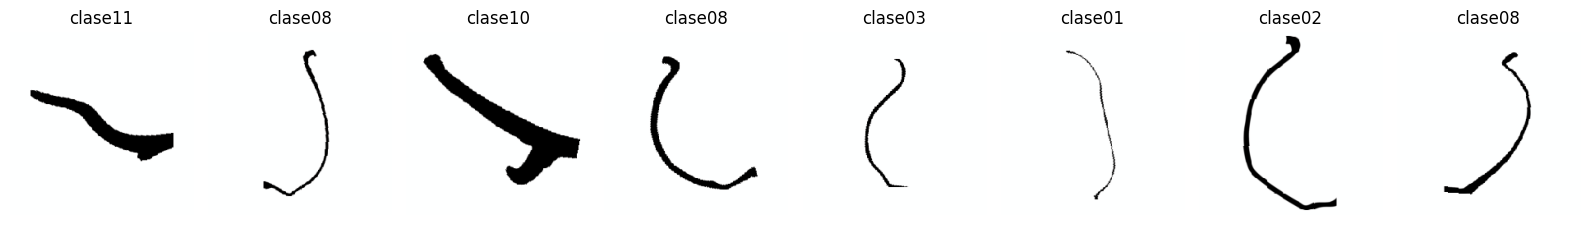

In [6]:
# Visualización rápida (sanity check)
graficar_lote_imagenes(loader=train_loader, nombres_clases=class_names, cantidad=8)
plt.show()

model = crear_modelo_transfer_learning(
    nombre_modelo=MODEL_NAME,
    num_classes=NUM_CLASSES,
    dispositivo=DEVICE,
)

In [7]:
# Criterio y optimizador
criterion = crear_criterio_entropia_cruzada()
optimizer = crear_optimizador_adam(model, learning_rate=LR)

In [8]:
# Descongelación gradual de layer4
def descongelar_al_iniciar_epoch(epoch):
    if maybe_unfreeze_layer4(
        model,
        optimizer,
        epoch,
        model_name=MODEL_NAME,
        unfreeze_epoch=UNFREEZE_EPOCH,
        backbone_lr=BACKBONE_LR,
    ):
        print(
            f"Epoch {epoch + 1}: se descongela layer4 con lr={BACKBONE_LR:.2e} "
            f"(head lr={LR:.2e})"
        )

In [9]:
# Entrenamiento y validación
historial = entrenar_modelo(
    modelo=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterio=criterion,
    optimizador=optimizer,
    dispositivo=DEVICE,
    epochs=EPOCHS,
    al_iniciar_epoch=descongelar_al_iniciar_epoch,
    al_finalizar_epoch=lambda metrica: print(
        describir_metricas_epoch(metrica, total_epochs=EPOCHS)
    ),
)

Epoch 1/30
Train Loss: 1.7917 | Train Acc: 0.4709 |Val Loss: 1.6638 |Val Acc: 0.5864
Tiempo de epoch: 0:00:08.054426 

Epoch 2/30
Train Loss: 1.3232 | Train Acc: 0.5820 |Val Loss: 1.3597 |Val Acc: 0.6173
Tiempo de epoch: 0:00:05.479487 

Epoch 3/30
Train Loss: 1.1471 | Train Acc: 0.6548 |Val Loss: 1.2148 |Val Acc: 0.6667
Tiempo de epoch: 0:00:05.388942 

Epoch 4/30
Train Loss: 1.0446 | Train Acc: 0.6733 |Val Loss: 1.1067 |Val Acc: 0.6728
Tiempo de epoch: 0:00:05.792517 

Epoch 5/30
Train Loss: 0.9408 | Train Acc: 0.7050 |Val Loss: 0.9977 |Val Acc: 0.6852
Tiempo de epoch: 0:00:05.392281 

Epoch 6/30
Train Loss: 0.8926 | Train Acc: 0.7315 |Val Loss: 1.0814 |Val Acc: 0.5679
Tiempo de epoch: 0:00:06.146029 

Epoch 7/30
Train Loss: 0.8754 | Train Acc: 0.7328 |Val Loss: 0.9409 |Val Acc: 0.7531
Tiempo de epoch: 0:00:05.521825 

Epoch 8/30
Train Loss: 0.8507 | Train Acc: 0.7328 |Val Loss: 0.9520 |Val Acc: 0.6790
Tiempo de epoch: 0:00:05.315327 

Epoch 9/30
Train Loss: 0.7746 | Train Acc: 0.746

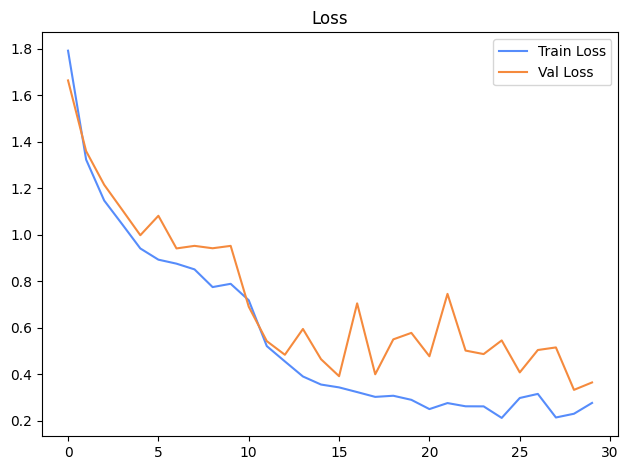

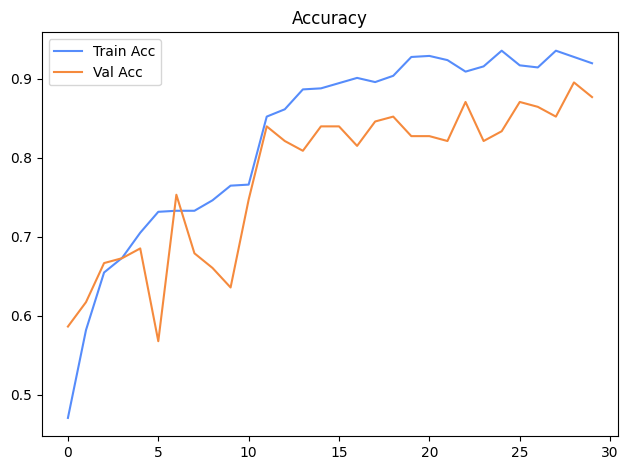

In [10]:
# Curvas de entrenamiento
graficar_historial_entrenamiento(historial)
plt.show()

Test Acc: 0.8773
              precision    recall  f1-score   support

     clase01       1.00      1.00      1.00         4
     clase02       1.00      0.14      0.25         7
     clase03       0.86      0.55      0.67        11
     clase04       1.00      1.00      1.00         1
     clase05       0.90      1.00      0.95         9
     clase06       0.80      0.57      0.67         7
     clase07       1.00      1.00      1.00         7
     clase08       0.75      0.95      0.84        42
     clase09       0.50      0.33      0.40         3
     clase10       0.96      1.00      0.98        54
     clase11       0.94      0.89      0.91        18

    accuracy                           0.88       163
   macro avg       0.88      0.77      0.79       163
weighted avg       0.89      0.88      0.86       163



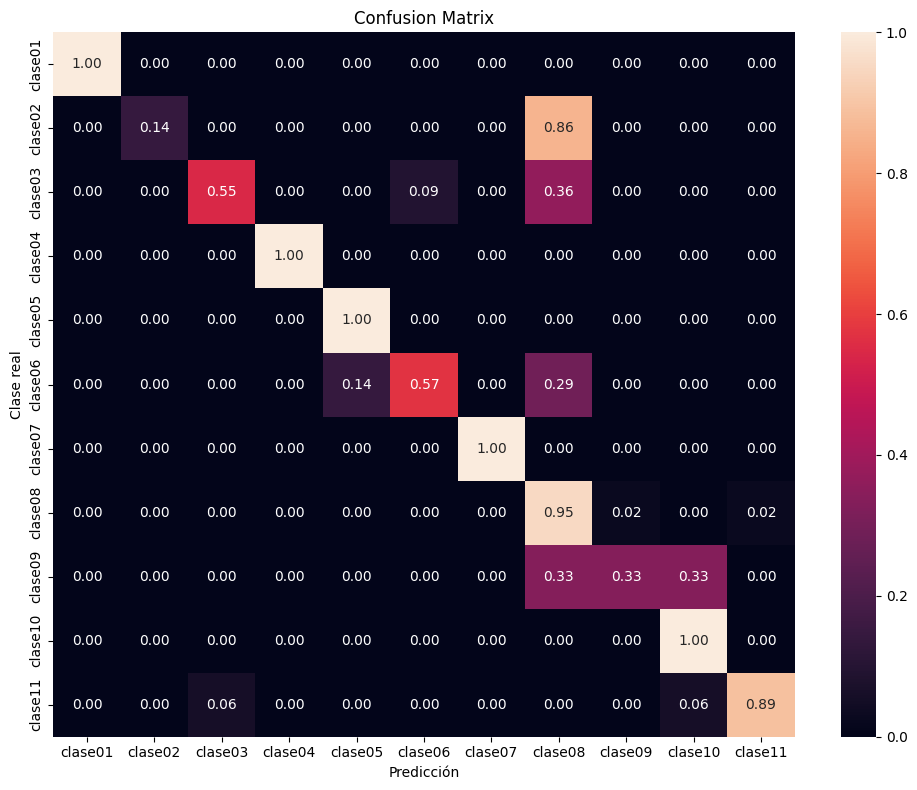

In [11]:
# Evaluación final
resultado_test = validar_modelo(
    modelo=model,
    loader=test_loader,
    criterio=criterion,
    dispositivo=DEVICE,
)
resultado_clasificacion = calcular_resultado_clasificacion(
    resultado=resultado_test,
    nombres_clases=class_names,
)

print(f"Test Acc: {resultado_test.accuracy:.4f}")
print(resultado_clasificacion.reporte)

graficar_matriz_confusion(
    matriz=resultado_clasificacion.matriz_confusion,
    nombres_clases=class_names,
)
plt.show()

In [12]:
# Guardado del modelo
ruta_modelo = guardar_pesos_modelo(
    modelo=model,
    ruta_destino=PATHS.OUTPUT_MODELS / f"model_{MODEL_NAME}_{RUN_NAME}.pth",
)
print(f"Modelo guardado en: {ruta_modelo}")

Modelo guardado en: /home/rafael/Dev/vasijas/output/models/model_resnet18_default.pth
